# Tugas Take-Home Sesi 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Dataset:** Oxford-IIIT Pet (subset 10 kelas: 5 kucing + 5 anjing) · **Arsitektur utama:** ResNet-18 (ImageNet1K_V1)

| Kode | Kondisi |
|---|---|
| B1 | Baseline from scratch (`weights=None`) |
| B2 | Feature extraction (backbone beku, hanya `fc`) |
| B3 | Progressive fine-tuning (`layer4` + `fc`, differential LR) |
| B4 | Uji kontrol augmentasi (B3 tanpa vs dengan augmentasi) |
| B5 | Arsitektur pembanding (EfficientNet-B0 / MobileNetV3-Small) — bonus |

**Cara pakai:** Runtime → GPU (T4), lalu *Run all*. Semua metrik tersimpan otomatis di folder `outputs/`.
Set `SMOKE = True` pada sel konfigurasi **hanya** untuk uji cepat tanpa unduhan (data sintetis, bobot acak) — hasilnya tidak valid untuk laporan.

**Sitasi kode:** pipeline mengacu pada starter code tugas, dokumentasi PyTorch/torchvision, dan resep reproduksibilitas PyTorch
(https://pytorch.org/docs/stable/notes/randomness.html). Grad-CAM: Selvaraju et al., 2017 (implementasi mandiri via hook).

In [1]:
import os, json, time, random, copy, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

# ====================== KONFIGURASI ======================
SMOKE = False          # True = dry-run sintetis (JANGAN dipakai untuk hasil laporan)
SEED = 42
CFG = dict(
    batch_size=32, max_epochs=30, patience=4, min_delta=1e-4,
    weight_decay=1e-2, lr_scratch=1e-3, lr_head=1e-3, lr_block=1e-4,
    num_workers=2, split=(0.70, 0.15, 0.15),
)
if SMOKE:
    CFG.update(max_epochs=2, patience=1, num_workers=0)

# 5 ras kucing + 5 ras anjing (nama sesuai torchvision; dicocokkan case-insensitive)
SELECTED = ["Abyssinian", "Bengal", "Birman", "Persian", "Siamese",
            "Beagle", "Pug", "Samoyed", "Shiba Inu", "Chihuahua"]

B4_BASE = "B3"                       # kondisi untuk uji augmentasi (B2 atau B3)
B5_ARCHS = ["efficientnet_b0"]       # tambahkan "mobilenet_v3_small" bila ingin keduanya

OUT = Path("outputs")
for d in ["logs", "figures", "checkpoints", "results", "data"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device: cuda | Tesla T4
torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 0. Reproduksibilitas

In [2]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

set_seed()

## 1. Data: subset 10 kelas, split stratified 70/15/15

Catatan anti-*data leakage*:
* Split dilakukan **sekali** pada indeks data mentah (belum ada transformasi/augmentasi), dengan `stratify`.
* Augmentasi hanya melekat pada *Dataset* train; val/test memakai transformasi deterministik.
* Citra dari split `trainval` dan `test` bawaan torchvision digabung dulu, lalu dibagi ulang (aturan tugas: split internal).

In [3]:
def load_items():
    """Return class_names, items (path atau PIL), labels (0..9)."""
    if SMOKE:
        rng = np.random.RandomState(0)
        names = [f"cls{i}" for i in range(10)]
        items, labels = [], []
        for c in range(10):
            for _ in range(40):
                base = np.array([(c*25) % 256, (c*60) % 256, (c*95) % 256])
                arr = np.clip(base + rng.randint(-40, 40, (64, 64, 3)), 0, 255).astype(np.uint8)
                items.append(Image.fromarray(arr)); labels.append(c)
        return names, items, np.array(labels)

    root = str(OUT / "data")
    tv = datasets.OxfordIIITPet(root=root, split="trainval", target_types="category", download=True)
    te = datasets.OxfordIIITPet(root=root, split="test", target_types="category", download=True)
    all_paths = list(tv._images) + list(te._images)
    all_labels = list(tv._labels) + list(te._labels)
    lookup = {c.lower(): i for i, c in enumerate(tv.classes)}
    missing = [n for n in SELECTED if n.lower() not in lookup]
    assert not missing, f"Nama kelas tidak ditemukan: {missing}\nTersedia: {tv.classes}"
    orig_ids = [lookup[n.lower()] for n in SELECTED]
    remap = {o: k for k, o in enumerate(orig_ids)}
    items, labels = [], []
    for p, l in zip(all_paths, all_labels):
        if l in remap:
            items.append(str(p)); labels.append(remap[l])
    return list(SELECTED), items, np.array(labels)

class_names, items, labels = load_items()
N = len(items)
print(f"Total citra subset: {N} | kelas: {class_names}")

idx = np.arange(N)
tr_idx, tmp_idx = train_test_split(idx, test_size=CFG["split"][1] + CFG["split"][2],
                                   stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=CFG["split"][2] / (CFG["split"][1] + CFG["split"][2]),
                                  stratify=labels[tmp_idx], random_state=SEED)

# --- pemeriksaan kebocoran data ---
assert len(set(tr_idx) & set(va_idx)) == 0 and len(set(tr_idx) & set(te_idx)) == 0 and len(set(va_idx) & set(te_idx)) == 0
assert len(tr_idx) + len(va_idx) + len(te_idx) == N

split_table = pd.DataFrame({
    "kelas": class_names,
    "train": np.bincount(labels[tr_idx], minlength=10),
    "val": np.bincount(labels[va_idx], minlength=10),
    "test": np.bincount(labels[te_idx], minlength=10)})
display(split_table)
print("Train/Val/Test:", len(tr_idx), len(va_idx), len(te_idx))

split_record = {"seed": SEED, "classes": class_names,
                "train": [str(items[i]) if not SMOKE else int(i) for i in tr_idx],
                "val": [str(items[i]) if not SMOKE else int(i) for i in va_idx],
                "test": [str(items[i]) if not SMOKE else int(i) for i in te_idx]}
json.dump(split_record, open(OUT / "results" / "split_indices.json", "w"))

100%|██████████| 792M/792M [00:38<00:00, 20.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.4MB/s]


Total citra subset: 1997 | kelas: ['Abyssinian', 'Bengal', 'Birman', 'Persian', 'Siamese', 'Beagle', 'Pug', 'Samoyed', 'Shiba Inu', 'Chihuahua']


,kelas,train,val,test
0,Abyssinian,138,30,30
1,Bengal,140,30,30
2,Birman,140,30,30
3,Persian,140,30,30
4,Siamese,139,30,30
5,Beagle,140,30,30
6,Pug,140,30,30
7,Samoyed,140,30,30
8,Shiba Inu,140,30,30
9,Chihuahua,140,30,30


Train/Val/Test: 1397 300 300


## 2. Transformasi & Dataset

In [4]:
weights_meta = models.ResNet18_Weights.IMAGENET1K_V1          # hanya untuk metadata transform (tidak mengunduh bobot)
MEAN, STD = weights_meta.transforms().mean, weights_meta.transforms().std

# Val/Test (dan skenario "tanpa augmentasi" B4): Resize 256 -> CenterCrop 224 -> Normalize (deterministik)
eval_tf = weights_meta.transforms()

# Train dengan augmentasi (sesuai starter code)
train_aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class PetSubset(Dataset):
    def __init__(self, items, labels, indices, transform):
        self.items, self.labels, self.indices, self.transform = items, labels, indices, transform
    def __len__(self): return len(self.indices)
    def raw(self, i):
        src = self.items[self.indices[i]]
        img = src if isinstance(src, Image.Image) else Image.open(src)
        return img.convert("RGB")
    def __getitem__(self, i):
        return self.transform(self.raw(i)), int(self.labels[self.indices[i]])

def make_loader(ds, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, num_workers=CFG["num_workers"],
                      worker_init_fn=seed_worker, generator=g, pin_memory=(device.type == "cuda"))

val_ds  = PetSubset(items, labels, va_idx, eval_tf)
test_ds = PetSubset(items, labels, te_idx, eval_tf)
test_raw = PetSubset(items, labels, te_idx, lambda x: x)       # untuk visualisasi failure analysis

## 3. Model builder (B1/B2/B3/B5)

`mode`: `scratch` (semua parameter dilatih), `fe` (hanya head), `ft` (blok terakhir + head, differential LR).
Urutan penting: **head diganti dulu → seluruh parameter dibekukan → head/blok dibuka kembali**, sehingga head baru selalu trainable.

In [5]:
def build_model(arch, mode, num_classes=10):
    pretrained = (mode != "scratch") and not SMOKE
    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        head, blocks = m.fc, [m.layer4]
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        head, blocks = m.classifier[1], [m.features[7], m.features[8]]
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
        head, blocks = m.classifier[3], [m.features[11], m.features[12]]
    else:
        raise ValueError(arch)

    if mode == "scratch":
        groups = [dict(name="all", params=list(m.parameters()), lr=CFG["lr_scratch"])]
    else:
        for p in m.parameters(): p.requires_grad = False
        for p in head.parameters(): p.requires_grad = True
        groups = [dict(name="head", params=list(head.parameters()), lr=CFG["lr_head"])]
        if mode == "ft":
            bp = []
            for b in blocks:
                for p in b.parameters(): p.requires_grad = True; bp.append(p)
            groups.insert(0, dict(name="last_block", params=bp, lr=CFG["lr_block"]))
    return m, groups

def count_params(m):
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in m.parameters())
    return tr, tot

def set_train_mode(m):
    """train() untuk modul yang dilatih; BatchNorm yang seluruh parameternya beku dipaksa eval()
    agar running_mean/var pretrained TIDAK tertimpa statistik data kecil (lihat Bagian A no.1 & 3)."""
    m.train()
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in mod.parameters()):
                mod.eval()

# --- verifikasi parameter (tips tugas: B2 ResNet-18 = 5.130) ---
for _mode in ["scratch", "fe", "ft"]:
    _m, _ = build_model("resnet18", _mode)
    tr, tot = count_params(_m)
    print(f"resnet18 [{_mode:7s}] trainable = {tr:>11,} / {tot:,}")
    if _mode == "fe": assert tr == 5130
del _m

resnet18 [scratch] trainable =  11,181,642 / 11,181,642
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]


resnet18 [fe     ] trainable =       5,130 / 11,181,642
resnet18 [ft     ] trainable =   8,398,858 / 11,181,642


## 4. Training loop dengan early stopping (monitor *validation loss*)

In [6]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device, non_blocking=True))
        pr = F.softmax(out, 1).cpu()
        ys.append(y); ps.append(pr.argmax(1)); probs.append(pr)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    set_train_mode(model) if train else model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            tot_loss += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot_loss / n, correct / n

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

RESULTS = {}

def run_experiment(code, name, arch, mode, aug):
    print(f"\n{'='*70}\n[{code}] {name} | arch={arch} mode={mode} aug={aug}\n{'='*70}")
    set_seed(SEED)
    model, groups = build_model(arch, mode); model.to(device)
    tr_params, tot_params = count_params(model)
    lr_desc = ", ".join(f"{g['name']}={g['lr']:g}" for g in groups)
    print(f"Trainable params: {tr_params:,} / {tot_params:,} | LR: {lr_desc}")

    optimizer = torch.optim.AdamW([dict(params=g["params"], lr=g["lr"]) for g in groups],
                                  weight_decay=CFG["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    train_ds = PetSubset(items, labels, tr_idx, train_aug_tf if aug else eval_tf)
    train_loader, val_loader = make_loader(train_ds, True), make_loader(val_ds, False)

    hist, best_loss, best_state, best_epoch, bad = [], float("inf"), None, 0, 0
    sync(); t0 = time.time()
    for ep in range(1, CFG["max_epochs"] + 1):
        te0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        sync()
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va,
                         epoch_sec=time.time() - te0, **{f"lr_{g['name']}": g["lr"] for g in groups}))
        print(f"ep {ep:02d} | train {tl:.4f}/{ta:.3f} | val {vl:.4f}/{va:.3f} | {hist[-1]['epoch_sec']:.1f}s")
        if vl < best_loss - CFG["min_delta"]:
            best_loss, best_epoch, bad = vl, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"Early stopping pada epoch {ep} (best epoch = {best_epoch})"); break
    sync(); total_sec = time.time() - t0

    model.load_state_dict(best_state)                       # kembalikan bobot terbaik
    clean_train_loader = make_loader(PetSubset(items, labels, tr_idx, eval_tf), False)
    _, train_acc_clean = run_epoch(model, clean_train_loader, criterion)   # akurasi train tanpa augmentasi
    val_loss, val_acc = run_epoch(model, val_loader, criterion)
    y, p, probs = predict(model, make_loader(test_ds, False))
    test_acc = accuracy_score(y, p); test_f1 = f1_score(y, p, average="macro")

    pd.DataFrame(hist).to_csv(OUT / "logs" / f"{code}_history.csv", index=False)
    pd.DataFrame({"test_idx": te_idx, "y_true": y, "y_pred": p, "confidence": probs.max(1),
                  **{f"p_{class_names[k]}": probs[:, k] for k in range(10)}}
                 ).to_csv(OUT / "logs" / f"{code}_test_predictions.csv", index=False)
    torch.save(model.state_dict(), OUT / "checkpoints" / f"{code}.pt")

    res = dict(code=code, name=name, arch=arch, mode=mode, augmentation=aug, seed=SEED,
               trainable_params=tr_params, total_params=tot_params, lr=lr_desc,
               epochs_run=len(hist), best_epoch=best_epoch, train_time_sec=round(total_sec, 1),
               sec_per_epoch=round(total_sec / len(hist), 2),
               train_acc_clean=train_acc_clean, val_acc=val_acc, val_loss=val_loss,
               gap_train_val=train_acc_clean - val_acc, test_acc=test_acc, test_macro_f1=test_f1)
    RESULTS[code] = res
    save_results()
    print(f"-> val_acc={val_acc:.4f} | test_acc={test_acc:.4f} | test_macroF1={test_f1:.4f} | {total_sec:.0f}s")
    return res

def save_results():
    rows = list(RESULTS.values())
    json.dump(rows, open(OUT / "results" / "raw_metrics.json", "w"), indent=2)
    pd.DataFrame(rows).to_csv(OUT / "results" / "raw_metrics.csv", index=False)

## 5. Eksperimen B1–B3 (semua dengan augmentasi standar)

In [7]:
run_experiment("B1", "Baseline from scratch", "resnet18", "scratch", aug=True)


[B1] Baseline from scratch | arch=resnet18 mode=scratch aug=True
Trainable params: 11,181,642 / 11,181,642 | LR: all=0.001
ep 01 | train 2.3348/0.183 | val 2.5100/0.200 | 16.9s
ep 02 | train 2.0376/0.258 | val 1.9369/0.313 | 16.3s
ep 03 | train 1.8919/0.328 | val 2.0740/0.253 | 14.7s
ep 04 | train 1.8208/0.339 | val 1.8785/0.383 | 14.8s
ep 05 | train 1.6685/0.399 | val 1.9054/0.377 | 15.8s
ep 06 | train 1.6199/0.402 | val 6.2450/0.183 | 16.4s
ep 07 | train 1.5417/0.438 | val 2.0742/0.363 | 15.0s
ep 08 | train 1.4264/0.505 | val 1.8105/0.433 | 14.8s
ep 09 | train 1.3237/0.523 | val 2.2307/0.320 | 14.9s
ep 10 | train 1.2693/0.544 | val 2.0012/0.397 | 14.8s
ep 11 | train 1.2250/0.560 | val 1.4280/0.520 | 14.9s
ep 12 | train 1.0877/0.616 | val 1.8901/0.453 | 14.8s
ep 13 | train 1.1050/0.603 | val 1.5870/0.500 | 15.7s
ep 14 | train 1.0211/0.634 | val 2.4074/0.393 | 15.4s
ep 15 | train 0.9209/0.665 | val 2.2278/0.397 | 14.8s
Early stopping pada epoch 15 (best epoch = 11)
-> val_acc=0.5200 |

{'code': 'B1',
 'name': 'Baseline from scratch',
 'arch': 'resnet18',
 'mode': 'scratch',
 'augmentation': True,
 'seed': 42,
 'trainable_params': 11181642,
 'total_params': 11181642,
 'lr': 'all=0.001',
 'epochs_run': 15,
 'best_epoch': 11,
 'train_time_sec': 230.1,
 'sec_per_epoch': 15.34,
 'train_acc_clean': 0.6148890479599141,
 'val_acc': 0.52,
 'val_loss': 1.428018601735433,
 'gap_train_val': 0.09488904795991404,
 'test_acc': 0.52,
 'test_macro_f1': 0.5045269550023637}

In [8]:
run_experiment("B2", "Feature extraction (head saja)", "resnet18", "fe", aug=True)


[B2] Feature extraction (head saja) | arch=resnet18 mode=fe aug=True
Trainable params: 5,130 / 11,181,642 | LR: head=0.001
ep 01 | train 1.2069/0.704 | val 0.4914/0.920 | 13.9s
ep 02 | train 0.4152/0.923 | val 0.2777/0.940 | 13.9s
ep 03 | train 0.2829/0.941 | val 0.2142/0.943 | 13.9s
ep 04 | train 0.2222/0.957 | val 0.1847/0.947 | 13.9s
ep 05 | train 0.1880/0.958 | val 0.1574/0.960 | 14.1s
ep 06 | train 0.1765/0.957 | val 0.1481/0.947 | 14.1s
ep 07 | train 0.1623/0.963 | val 0.1302/0.967 | 14.1s
ep 08 | train 0.1383/0.966 | val 0.1188/0.963 | 13.9s
ep 09 | train 0.1323/0.970 | val 0.1140/0.967 | 13.9s
ep 10 | train 0.1159/0.976 | val 0.1165/0.963 | 14.1s
ep 11 | train 0.1098/0.974 | val 0.1079/0.967 | 13.9s
ep 12 | train 0.1015/0.976 | val 0.1090/0.967 | 14.1s
ep 13 | train 0.1007/0.979 | val 0.1105/0.967 | 14.0s
ep 14 | train 0.1047/0.972 | val 0.1052/0.963 | 14.0s
ep 15 | train 0.1004/0.974 | val 0.1001/0.970 | 14.1s
ep 16 | train 0.0907/0.976 | val 0.0980/0.967 | 13.9s
ep 17 | trai

{'code': 'B2',
 'name': 'Feature extraction (head saja)',
 'arch': 'resnet18',
 'mode': 'fe',
 'augmentation': True,
 'seed': 42,
 'trainable_params': 5130,
 'total_params': 11181642,
 'lr': 'head=0.001',
 'epochs_run': 23,
 'best_epoch': 19,
 'train_time_sec': 320.5,
 'sec_per_epoch': 13.93,
 'train_acc_clean': 0.984251968503937,
 'val_acc': 0.97,
 'val_loss': 0.08323400671283404,
 'gap_train_val': 0.014251968503937062,
 'test_acc': 0.97,
 'test_macro_f1': 0.9699113065583049}

In [9]:
run_experiment("B3", "Progressive fine-tuning (layer4+fc, differential LR)", "resnet18", "ft", aug=True)


[B3] Progressive fine-tuning (layer4+fc, differential LR) | arch=resnet18 mode=ft aug=True
Trainable params: 8,398,858 / 11,181,642 | LR: last_block=0.0001, head=0.001
ep 01 | train 0.6727/0.807 | val 0.1255/0.957 | 13.8s
ep 02 | train 0.1384/0.963 | val 0.1178/0.963 | 16.9s
ep 03 | train 0.0791/0.984 | val 0.0709/0.970 | 14.1s
ep 04 | train 0.0571/0.988 | val 0.0671/0.970 | 14.2s
ep 05 | train 0.0364/0.994 | val 0.0565/0.980 | 13.9s
ep 06 | train 0.0328/0.991 | val 0.0751/0.970 | 13.9s
ep 07 | train 0.0356/0.990 | val 0.0596/0.983 | 13.6s
ep 08 | train 0.0263/0.993 | val 0.0659/0.980 | 14.6s
ep 09 | train 0.0231/0.994 | val 0.0516/0.980 | 13.7s
ep 10 | train 0.0115/0.999 | val 0.0569/0.983 | 14.0s
ep 11 | train 0.0148/0.998 | val 0.1010/0.957 | 13.7s
ep 12 | train 0.0108/0.997 | val 0.0798/0.967 | 13.9s
ep 13 | train 0.0083/0.999 | val 0.0740/0.980 | 14.0s
Early stopping pada epoch 13 (best epoch = 9)
-> val_acc=0.9800 | test_acc=0.9533 | test_macroF1=0.9532 | 184s


{'code': 'B3',
 'name': 'Progressive fine-tuning (layer4+fc, differential LR)',
 'arch': 'resnet18',
 'mode': 'ft',
 'augmentation': True,
 'seed': 42,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'lr': 'last_block=0.0001, head=0.001',
 'epochs_run': 13,
 'best_epoch': 9,
 'train_time_sec': 184.4,
 'sec_per_epoch': 14.19,
 'train_acc_clean': 0.9992841803865425,
 'val_acc': 0.98,
 'val_loss': 0.05162378790477912,
 'gap_train_val': 0.01928418038654256,
 'test_acc': 0.9533333333333334,
 'test_macro_f1': 0.9532387503824014}

## 6. B4 — Uji kontrol augmentasi
Kondisi dasar dipilih lewat `B4_BASE`. Skenario **dengan** augmentasi = hasil B1–B3 yang sama (seed & konfigurasi identik, sehingga tidak dijalankan ulang);
skenario **tanpa** augmentasi dijalankan di sini. Kolom `gap_train_val` memakai akurasi train **tanpa augmentasi** pada bobot terbaik.

In [10]:
base = RESULTS[B4_BASE]
RESULTS["B4-2"] = {**base, "code": "B4-2", "name": f"{B4_BASE} DENGAN augmentasi (= {B4_BASE})"}
run_experiment("B4-1", f"{B4_BASE} TANPA augmentasi", base["arch"], base["mode"], aug=False)
save_results()


[B4-1] B3 TANPA augmentasi | arch=resnet18 mode=ft aug=False
Trainable params: 8,398,858 / 11,181,642 | LR: last_block=0.0001, head=0.001
ep 01 | train 0.5855/0.843 | val 0.1266/0.957 | 9.0s
ep 02 | train 0.0697/0.988 | val 0.0721/0.983 | 10.0s
ep 03 | train 0.0238/0.999 | val 0.0645/0.990 | 10.5s
ep 04 | train 0.0129/0.999 | val 0.0545/0.987 | 10.3s
ep 05 | train 0.0073/1.000 | val 0.0507/0.990 | 8.9s
ep 06 | train 0.0059/1.000 | val 0.0521/0.983 | 10.0s
ep 07 | train 0.0046/1.000 | val 0.0493/0.990 | 10.0s
ep 08 | train 0.0036/1.000 | val 0.0448/0.990 | 11.2s
ep 09 | train 0.0024/1.000 | val 0.0439/0.990 | 9.4s
ep 10 | train 0.0028/0.999 | val 0.0406/0.993 | 10.5s
ep 11 | train 0.0026/1.000 | val 0.0478/0.983 | 10.2s
ep 12 | train 0.0017/1.000 | val 0.0399/0.990 | 10.3s
ep 13 | train 0.0014/1.000 | val 0.0469/0.990 | 8.7s
ep 14 | train 0.0010/1.000 | val 0.0393/0.990 | 10.6s
ep 15 | train 0.0011/1.000 | val 0.0470/0.983 | 10.3s
ep 16 | train 0.0008/1.000 | val 0.0421/0.990 | 10.0s
e

## 7. B5 (Bonus) — Arsitektur efisien
Strategi (feature extraction vs fine-tuning) dipilih otomatis dari B2/B3 berdasarkan **validation loss** (bukan test set, agar tidak ada *test-set selection*).

In [11]:
best_strat = min(["B2", "B3"], key=lambda c: RESULTS[c]["val_loss"])
mode5 = RESULTS[best_strat]["mode"]
print("Strategi terbaik B2/B3 berdasarkan val_loss:", best_strat, "->", mode5)
for arch in B5_ARCHS:
    run_experiment(f"B5-{arch}", f"{arch} ({mode5})", arch, mode5, aug=True)

Strategi terbaik B2/B3 berdasarkan val_loss: B3 -> ft

[B5-efficientnet_b0] efficientnet_b0 (ft) | arch=efficientnet_b0 mode=ft aug=True
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 182MB/s]

Trainable params: 1,142,202 / 4,020,358 | LR: last_block=0.0001, head=0.001


ep 01 | train 0.9831/0.803 | val 0.1832/0.963 | 14.2s
ep 02 | train 0.2186/0.944 | val 0.0938/0.983 | 14.7s
ep 03 | train 0.1393/0.960 | val 0.0657/0.987 | 14.1s
ep 04 | train 0.0952/0.976 | val 0.0530/0.987 | 14.4s
ep 05 | train 0.0761/0.979 | val 0.0452/0.987 | 14.1s
ep 06 | train 0.0782/0.978 | val 0.0349/0.993 | 13.9s
ep 07 | train 0.0725/0.979 | val 0.0348/0.990 | 14.3s
ep 08 | train 0.0554/0.984 | val 0.0393/0.983 | 14.0s
ep 09 | train 0.0564/0.979 | val 0.0327/0.993 | 14.4s
ep 10 | train 0.0545/0.985 | val 0.0305/0.990 | 14.2s
ep 11 | train 0.0412/0.988 | val 0.0264/0.997 | 14.2s
ep 12 | train 0.0292/0.994 | val 0.0298/0.993 | 14.1s
ep 13 | train 0.0322/0.991 | val 0.0302/0.987 | 14.1s
ep 14 | train 0.0326/0.986 | val 0.0296/0.990 | 14.6s
ep 15 | train 0.0272/0.994 | val 0.0370/0.977 | 14.1s
Early stopping pada epoch 15 (best epoch = 11)
-> val_acc=0.9967 | test_acc=0.9767 | test_macroF1=0.9767 | 214s


## 8. C1 — Tabel konsolidasi & kurva belajar

In [12]:
def consolidated_table():
    order = [c for c in ["B1", "B2", "B3", "B4-1", "B4-2"] if c in RESULTS] + [c for c in RESULTS if c.startswith("B5")]
    df = pd.DataFrame([RESULTS[c] for c in order])
    t = pd.DataFrame({
        "Kode": df.code, "Strategi": df.name, "Trainable Params": df.trainable_params.map("{:,}".format),
        "Learning Rate": df.lr, "Epoch Konvergen (best)": df.best_epoch, "Epoch Dijalankan": df.epochs_run,
        "Waktu Latih (s)": df.train_time_sec, "Acc Train (clean)": df.train_acc_clean.round(4),
        "Acc Val": df.val_acc.round(4), "Gap Train-Val": df.gap_train_val.round(4),
        "Acc Test": df.test_acc.round(4), "Macro F1 Test": df.test_macro_f1.round(4)})
    return t

tbl = consolidated_table()
display(tbl)
tbl.to_csv(OUT / "results" / "tabel_konsolidasi.csv", index=False)
header = "| " + " | ".join(tbl.columns) + " |\n|" + "---|" * len(tbl.columns) + "\n"
rows = "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in tbl.values)
open(OUT / "results" / "tabel_konsolidasi.md", "w").write(header + rows)

,Kode,Strategi,Trainable Params,Learning Rate,Epoch Konvergen (best),Epoch Dijalankan,Waktu Latih (s),Acc Train (clean),Acc Val,Gap Train-Val,Acc Test,Macro F1 Test
0,B1,Baseline from scratch,"11,181,642",all=0.001,11,15,230.1,0.6149,0.5200,0.0949,0.5200,0.5045
1,B2,Feature extraction (head saja),"5,130",head=0.001,19,23,320.5,0.9843,0.9700,0.0143,0.9700,0.9699
2,B3,"Progressive fine-tuning (layer4+fc, differenti...","8,398,858","last_block=0.0001, head=0.001",9,13,184.4,0.9993,0.9800,0.0193,0.9533,0.9532
3,B4-1,B3 TANPA augmentasi,"8,398,858","last_block=0.0001, head=0.001",19,23,229.1,1.0000,0.9900,0.0100,0.9600,0.9599
4,B4-2,B3 DENGAN augmentasi (= B3),"8,398,858","last_block=0.0001, head=0.001",9,13,184.4,0.9993,0.9800,0.0193,0.9533,0.9532
5,B5-efficientnet_b0,efficientnet_b0 (ft),"1,142,202","last_block=0.0001, head=0.001",11,15,213.8,0.9971,0.9967,0.0005,0.9767,0.9767


1065

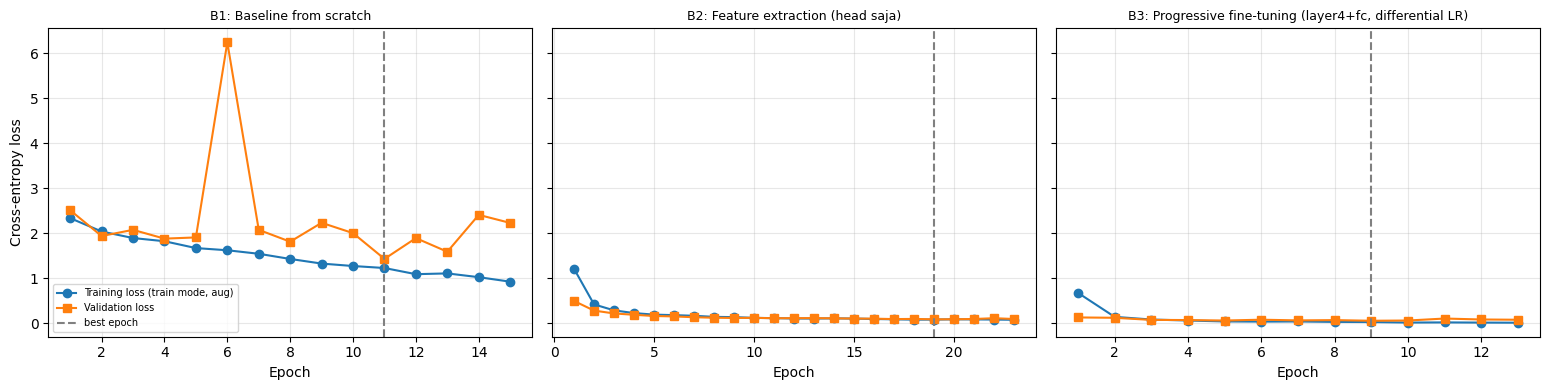

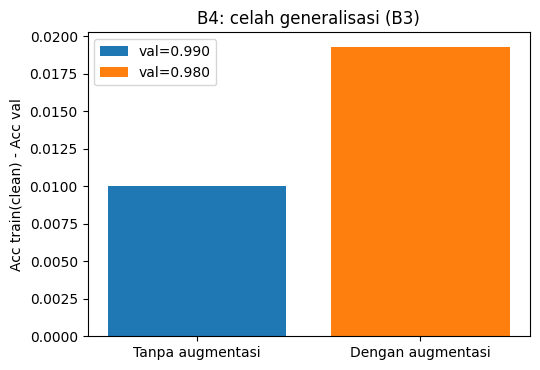

In [13]:
def plot_curves(codes, fname="kurva_B1_B2_B3.png"):
    fig, axes = plt.subplots(1, len(codes), figsize=(5.2 * len(codes), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, codes):
        h = pd.read_csv(OUT / "logs" / f"{c}_history.csv")
        ax.plot(h.epoch, h.train_loss, "o-", label="Training loss (train mode, aug)")
        ax.plot(h.epoch, h.val_loss, "s-", label="Validation loss")
        ax.axvline(RESULTS[c]["best_epoch"], ls="--", c="gray", label="best epoch")
        ax.set_title(f"{c}: {RESULTS[c]['name']}", fontsize=9); ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
    axes[0].set_ylabel("Cross-entropy loss"); axes[0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / "figures" / fname, dpi=200); plt.show()

plot_curves(["B1", "B2", "B3"])

# gap overfitting B4
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for c, lab in [("B4-1", "Tanpa augmentasi"), ("B4-2", "Dengan augmentasi")]:
    r = RESULTS[c]; ax.bar([lab], [r["gap_train_val"]], label=f"val={r['val_acc']:.3f}")
ax.set_ylabel("Acc train(clean) - Acc val"); ax.set_title(f"B4: celah generalisasi ({B4_BASE})"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "B4_gap.png", dpi=200); plt.show()

## 9. C3 — Failure analysis
Model terbaik dipilih berdasarkan **val_acc** (tie-break: val_loss) di antara B1–B4 (B5 ikut jika lebih baik).
Sampel yang ditampilkan: kesalahan dengan *confidence* tertinggi (tanpa *cherry-picking*; kriteria ini dicantumkan di laporan).

Model terbaik: B5-efficientnet_b0 efficientnet_b0 (ft)
Salah prediksi: 7 / 300 citra test


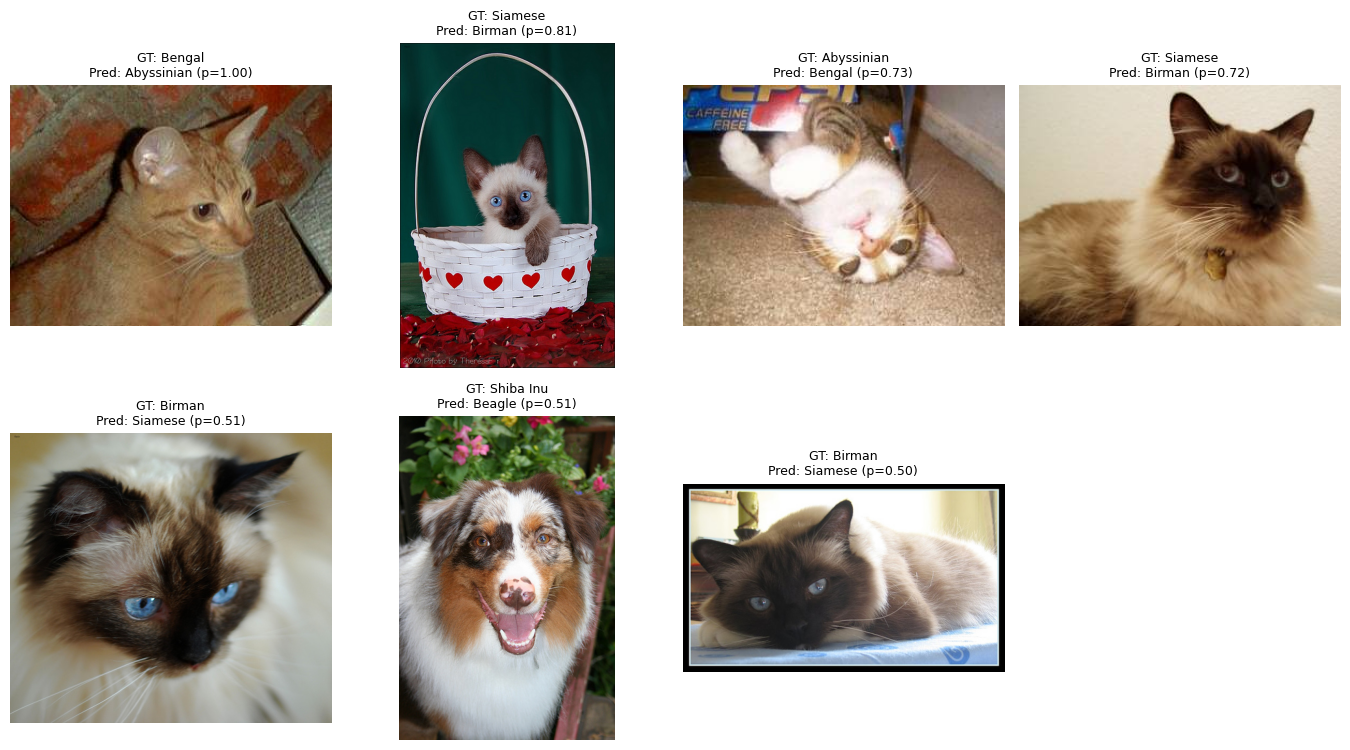

,test_idx,ground_truth,prediksi,confidence,hipotesis_penyebab
229,137,Bengal,Abyssinian,0.997982,(ISI MANUAL setelah melihat citra)
277,977,Siamese,Birman,0.813496,(ISI MANUAL setelah melihat citra)
18,1009,Abyssinian,Bengal,0.727448,(ISI MANUAL setelah melihat citra)
231,1916,Siamese,Birman,0.724487,(ISI MANUAL setelah melihat citra)
67,1343,Birman,Siamese,0.510758,(ISI MANUAL setelah melihat citra)
110,907,Shiba Inu,Beagle,0.507340,(ISI MANUAL setelah melihat citra)
239,1387,Birman,Siamese,0.499181,(ISI MANUAL setelah melihat citra)


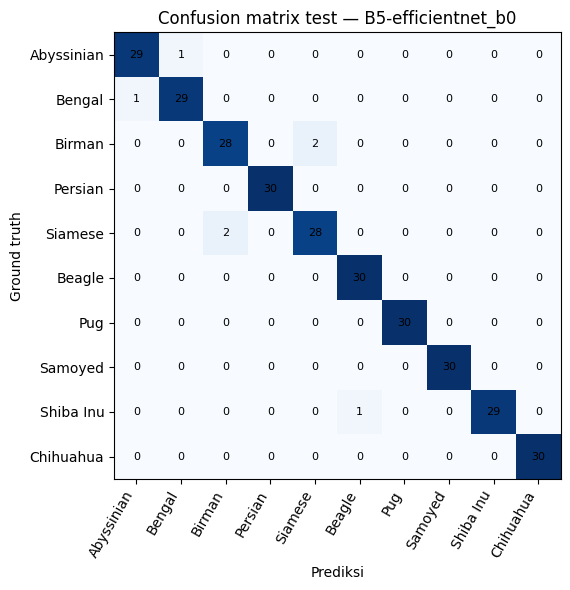

              precision    recall  f1-score   support

  Abyssinian      0.967     0.967     0.967        30
      Bengal      0.967     0.967     0.967        30
      Birman      0.933     0.933     0.933        30
     Persian      1.000     1.000     1.000        30
     Siamese      0.933     0.933     0.933        30
      Beagle      0.968     1.000     0.984        30
         Pug      1.000     1.000     1.000        30
     Samoyed      1.000     1.000     1.000        30
   Shiba Inu      1.000     0.967     0.983        30
   Chihuahua      1.000     1.000     1.000        30

    accuracy                          0.977       300
   macro avg      0.977     0.977     0.977       300
weighted avg      0.977     0.977     0.977       300



In [14]:
cands = {c: r for c, r in RESULTS.items() if c != "B4-2"}
best_code = sorted(cands, key=lambda c: (-cands[c]["val_acc"], cands[c]["val_loss"]))[0]
print("Model terbaik:", best_code, RESULTS[best_code]["name"])

pred = pd.read_csv(OUT / "logs" / f"{best_code}_test_predictions.csv")
wrong = pred[pred.y_true != pred.y_pred].sort_values("confidence", ascending=False)
print(f"Salah prediksi: {len(wrong)} / {len(pred)} citra test")

show = wrong.head(8)
if len(show):
    n = len(show); cols = 4; rws = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(3.4 * cols, 3.8 * rws)); axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, (_, r) in zip(axes, show.iterrows()):
        pos = int(np.where(te_idx == r.test_idx)[0][0])
        ax.imshow(test_raw.raw(pos))
        ax.set_title(f"GT: {class_names[int(r.y_true)]}\nPred: {class_names[int(r.y_pred)]} (p={r.confidence:.2f})", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "failure_analysis.png", dpi=200); plt.show()

    fa = show.assign(ground_truth=show.y_true.map(lambda k: class_names[int(k)]),
                     prediksi=show.y_pred.map(lambda k: class_names[int(k)]),
                     hipotesis_penyebab="(ISI MANUAL setelah melihat citra)")[
        ["test_idx", "ground_truth", "prediksi", "confidence", "hipotesis_penyebab"]]
    fa.to_csv(OUT / "results" / "failure_analysis.csv", index=False); display(fa)

# confusion matrix & F1 per kelas
y, p = pred.y_true.values, pred.y_pred.values
cm = confusion_matrix(y, p, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=60, ha="right"); ax.set_yticklabels(class_names)
for i in range(10):
    for j in range(10): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix test — {best_code}")
plt.tight_layout(); plt.savefig(OUT / "figures" / "confusion_matrix.png", dpi=200); plt.show()
print(classification_report(y, p, target_names=class_names, digits=3))

## 10. C5 (Opsional) — Grad-CAM `layer4`: sebelum vs sesudah fine-tuning
*Sebelum* = B2 (`layer4` masih bobot ImageNet, hanya head yang dilatih); *sesudah* = B3 (`layer4` di-fine-tune). Membutuhkan B2 & B3 (ResNet-18).

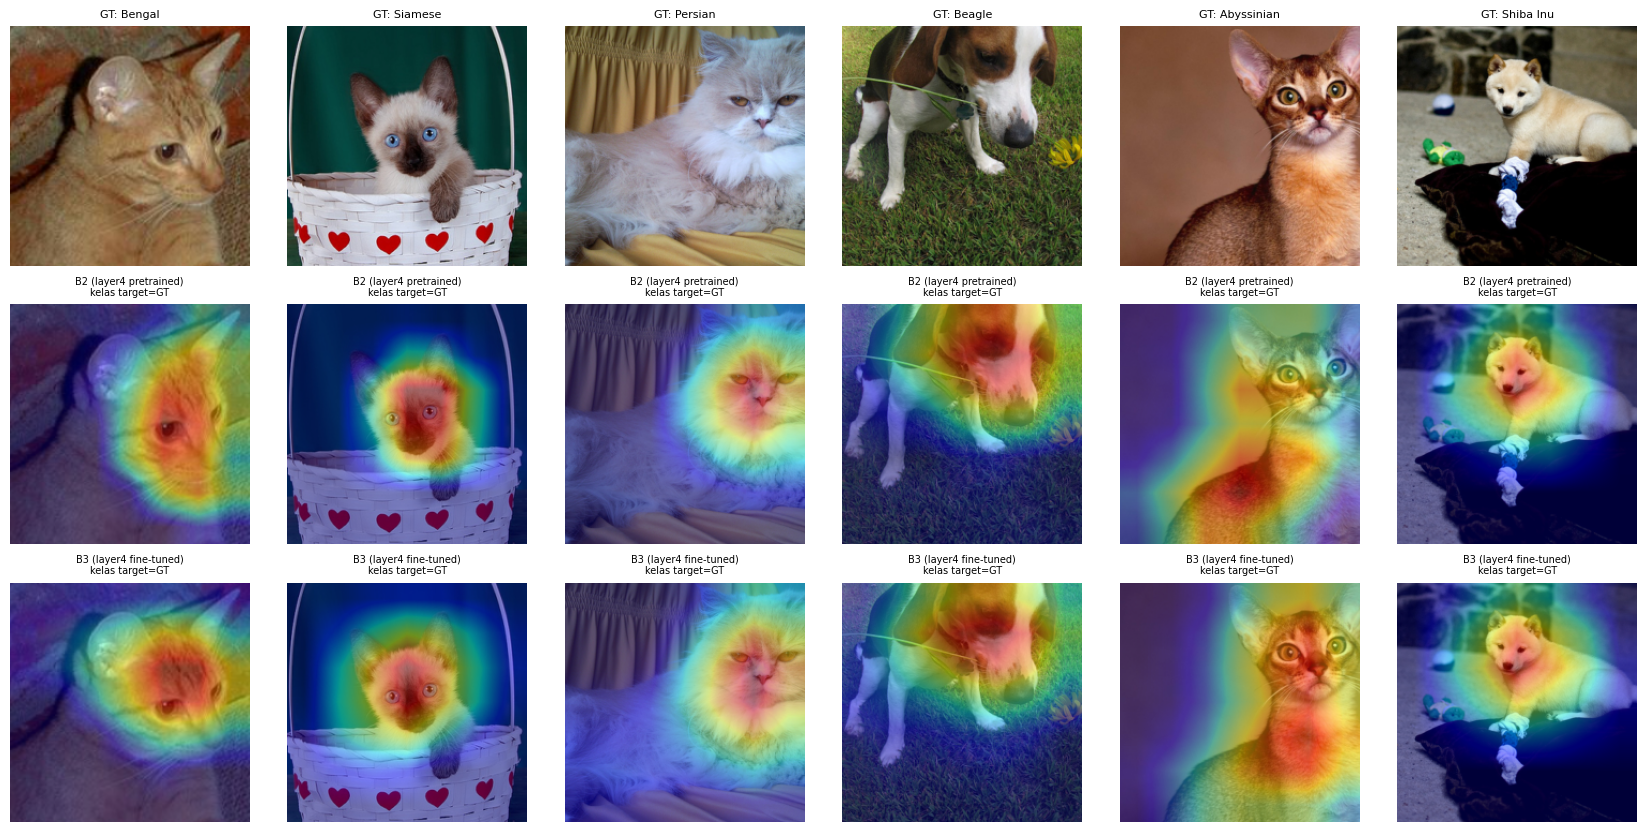

In [15]:
def gradcam(model, x, class_idx=None):
    model.eval(); store = {}
    def fwd(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd)
    x = x.clone().requires_grad_(True)                  # perlu agar graf terbentuk meski backbone beku
    logits = model(x)
    k = int(logits.argmax(1)) if class_idx is None else class_idx
    model.zero_grad(); logits[0, k].backward(); h.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), k

def load_ckpt(code, mode):
    m, _ = build_model("resnet18", mode); m.load_state_dict(torch.load(OUT / "checkpoints" / f"{code}.pt", map_location=device))
    return m.to(device).eval()

m_before, m_after = load_ckpt("B2", "fe"), load_ckpt("B3", "ft")
sel = list(wrong.test_idx.head(2).map(lambda t: int(np.where(te_idx == t)[0][0]))) + [0, 1, 2, 3]
sel = sel[:6]
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(3, len(sel), figsize=(2.8 * len(sel), 8.4))
for j, pos in enumerate(sel):
    x, yk = test_ds[pos]; xb = x.unsqueeze(0).to(device)
    img = (x * std_t + mean_t).permute(1, 2, 0).clamp(0, 1).numpy()
    axes[0, j].imshow(img); axes[0, j].set_title(f"GT: {class_names[yk]}", fontsize=8)
    for r, (mdl, lab) in enumerate([(m_before, "B2 (layer4 pretrained)"), (m_after, "B3 (layer4 fine-tuned)")], start=1):
        cam, k = gradcam(mdl, xb, class_idx=yk)
        axes[r, j].imshow(img); axes[r, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, j].set_title(f"{lab}\nkelas target=GT", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures" / "gradcam_before_after.png", dpi=200); plt.show()

## 11. Catatan lingkungan eksperimen (untuk reproduksibilitas)

In [16]:
env = dict(seed=SEED, smoke_mode=SMOKE, config=CFG, classes=class_names,
           n_train=int(len(tr_idx)), n_val=int(len(va_idx)), n_test=int(len(te_idx)),
           torch=torch.__version__, torchvision=torchvision.__version__, python=platform.python_version(),
           device=(torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"),
           b4_base=B4_BASE, b5_archs=B5_ARCHS)
json.dump(env, open(OUT / "results" / "environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))
if SMOKE: print("\n!!! SMOKE MODE AKTIF — hasil di atas TIDAK valid untuk laporan !!!")

{
  "seed": 42,
  "smoke_mode": false,
  "config": {
    "batch_size": 32,
    "max_epochs": 30,
    "patience": 4,
    "min_delta": 0.0001,
    "weight_decay": 0.01,
    "lr_scratch": 0.001,
    "lr_head": 0.001,
    "lr_block": 0.0001,
    "num_workers": 2,
    "split": [
      0.7,
      0.15,
      0.15
    ]
  },
  "classes": [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Persian",
    "Siamese",
    "Beagle",
    "Pug",
    "Samoyed",
    "Shiba Inu",
    "Chihuahua"
  ],
  "n_train": 1397,
  "n_val": 300,
  "n_test": 300,
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "python": "3.13.15",
  "device": "Tesla T4",
  "b4_base": "B3",
  "b5_archs": [
    "efficientnet_b0"
  ]
}


In [17]:
!zip -r outputs.zip outputs

Streaming output truncated to the last 5000 lines.
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/german_shorthaired_170.png (deflated 8%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/._samoyed_132.png (deflated 36%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/._american_pit_bull_terrier_98.png (deflated 36%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/._Russian_Blue_201.png (deflated 36%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/english_cocker_spaniel_13.png (deflated 9%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/german_shorthaired_127.png (deflated 4%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/german_shorthaired_180.png (deflated 5%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/._staffordshire_bull_terrier_96.png (deflated 36%)
  adding: outputs/data/oxford-iiit-pet/annotations/trimaps/._saint_bernard_41.png (deflated 36%)
  adding: outputs/data/oxford-iiit-pet/an